<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# A printed total can balance while a line is wrong

Extract a PDF table into typed invoice lines, recompute each amount, and locate the extracted items on a rendered page. Then switch to a variant with an intentionally stale printed amount. The question is whether checking only the printed total is enough.

**This two-page PDF is entirely synthetic.** It contains five invented items, quantities and USD prices, with no taxes, discounts or shipping. Page 1 is arithmetically consistent. Page 2 changes a quantity while deliberately leaving the corresponding printed line amount and total unchanged. The PDF generator and byte-hash provenance are bundled; no real customer or transaction is involved.

## Choose a document variant

`PAGE_NUMBER` accepts **1** or **2**, default **1**. PDF page numbers are one-based; table rows and columns returned by this worker are zero-based. Restart and run all after changing the page. Both variants use the same known ruled-table layout, so the experiment changes document content without changing the parsing strategy.

In [1]:
PAGE_NUMBER = 1  # 1: consistent baseline; 2: quantity changed, printed amounts intentionally stale

In [2]:
import hashlib
import io
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle
from PIL import Image

from notebook_support import finish, theme

assert type(PAGE_NUMBER) is int and PAGE_NUMBER in {1, 2}
manifest = json.loads(Path("fixtures/provenance.json").read_text())
assert hashlib.sha256((Path("fixtures") / manifest["file"]).read_bytes()).hexdigest() == manifest["sha256"]
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pdf/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pdf/notebooks/pyproject.toml.

## Extract structure and rendering through the worker

The visible Git command pins the worker and its tested PDF libraries in a separate `uvx` environment. Notebook Python does not parse the document. Table cells, words, page geometry and the PNG render all come from the real worker through VGI and are materialized once.

Scalars take positional arguments; structure functions take named `pdf :=` and `page :=` arguments. The render requests **144 DPI**. Word coordinates and page sizes are **PDF points** (72 points per inch), measured from the page’s top-left for the vertical coordinate. The plot maps raster pixels back to those point coordinates.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pdf' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pdfplumber==0.11.10 --with pypdfium2==5.15.0 --with pikepdf==10.17.0 --with Pillow==13.0.0 --from git+https://github.com/Query-farm/vgi-pdf@20e1590922c3ec394e53141b6abaffbb7ff4d7b9 vgi-pdf-worker');
CREATE TABLE document AS SELECT pdf.main.page_count('fixtures/invoice_variants.pdf') AS page_count;
CREATE TABLE page_geometry AS SELECT * FROM pdf.main.pages(pdf := 'fixtures/invoice_variants.pdf');
CREATE TABLE cells AS SELECT * FROM pdf.main.tables(pdf := 'fixtures/invoice_variants.pdf',page := {{PAGE_NUMBER}});
CREATE TABLE words AS SELECT * FROM pdf.main.words(pdf := 'fixtures/invoice_variants.pdf',page := {{PAGE_NUMBER}});
CREATE TABLE rendered AS SELECT pdf.main.render_page('fixtures/invoice_variants.pdf',{{PAGE_NUMBER}},144) AS png;

,Count


In [4]:
%%sql geometry <<
SELECT p.*,d.page_count,(SELECT count(*) FROM cells) AS extracted_cells,
 (SELECT count(*) FROM words) AS extracted_words
FROM page_geometry p CROSS JOIN document d WHERE p.page={{PAGE_NUMBER}};

In [5]:
display(geometry)

,page,width,height,rotation,page_count,extracted_cells,extracted_words
0,1,612.0,792.0,0,2,28,57


## Use header text to name columns, then cast

`tables` returns one row per cell. We read the header row of table 0, match its labels to columns, and pivot each following row. This rule is specific to the known synthetic layout; it is not a general invoice parser. A different document needs its own schema and extraction checks.

The TOTAL row is kept separately. Quantities become integers, money becomes exact `DECIMAL(12,2)`, and `TRY_CAST` keeps parsing failures visible as NULL. No binary floating-point values are used for reconciliation.

In [6]:
%%sql
CREATE TABLE headers AS SELECT col,lower(value) AS label FROM cells WHERE table_index=0 AND "row"=0;
CREATE TABLE invoice_rows AS
SELECT c.page,c.table_index,c."row" AS row_index,
 max(c.value) FILTER(WHERE h.label='sku') AS sku,
 max(c.value) FILTER(WHERE h.label='qty') AS quantity_text,
 max(c.value) FILTER(WHERE h.label='unit') AS unit_text,
 max(c.value) FILTER(WHERE h.label='amount') AS amount_text
FROM cells c JOIN headers h USING(col) WHERE c.table_index=0 AND c."row">0
GROUP BY c.page,c.table_index,c."row";
CREATE TABLE line_items AS
SELECT page,row_index,sku,try_cast(quantity_text AS INTEGER) AS quantity,
 try_cast(unit_text AS DECIMAL(12,2)) AS unit_price,
 try_cast(amount_text AS DECIMAL(12,2)) AS printed_amount
FROM invoice_rows WHERE sku<>'TOTAL';
CREATE TABLE reconciled AS
SELECT *,quantity*unit_price AS computed_amount,
 quantity*unit_price-printed_amount AS difference,
 quantity*unit_price<>printed_amount AS discrepancy
FROM line_items;
CREATE TABLE invoice_total AS
SELECT try_cast(amount_text AS DECIMAL(12,2)) AS printed_total FROM invoice_rows WHERE sku='TOTAL';

,Count


In [7]:
%%sql lines <<
SELECT * FROM reconciled ORDER BY row_index;

In [8]:
display(lines)

,page,row_index,sku,quantity,unit_price,printed_amount,computed_amount,difference,discrepancy
0,1,1,TAPE,10,12.5,125.0,125.0,0.0,False
1,1,2,BOXES,4,20.0,80.0,80.0,0.0,False
2,1,3,GLOVES,3,15.0,45.0,45.0,0.0,False
3,1,4,LABELS,8,2.5,20.0,20.0,0.0,False
4,1,5,FOAM,6,7.5,45.0,45.0,0.0,False


## Locate extracted items on the page

Join each SKU to an identical extracted word on the same page. These SKU labels occur once per page in the fixture; the uniqueness check below guards that assumption. Boxes mark **SKU word bounds**, not the whole table row. Rust-colored boxes flag a line whose arithmetic differs; green boxes mark agreement.

The chart shows a fixed content crop of the full worker render, with axes in PDF points and the vertical origin at the top. Geometry and word coordinates remain in the same coordinate system even though the raster uses two pixels per point at 144 DPI.

In [9]:
%%sql boxes <<
SELECT r.sku,r.discrepancy,w.x0,w.top,w.x1,w.bottom
FROM reconciled r JOIN words w ON r.page=w.page AND r.sku=w.text ORDER BY r.row_index;

In [10]:
%%sql raster <<
SELECT png FROM rendered;

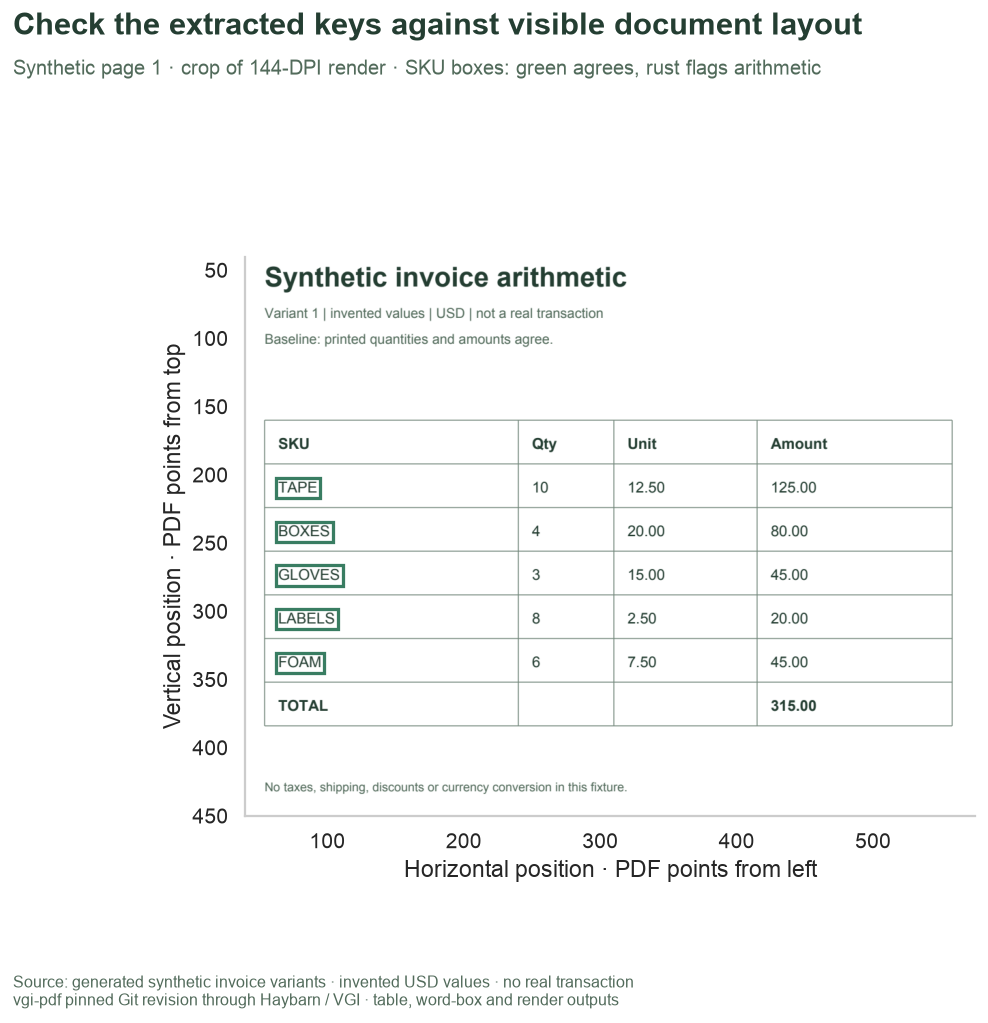

In [11]:
assert raster.png.iloc[0] is not None, "Worker could not render the selected PDF page"
page_image = Image.open(io.BytesIO(bytes(raster.png.iloc[0])))
width = float(geometry.width.iloc[0])
height = float(geometry.height.iloc[0])
assert page_image.size == (round(width * 2), round(height * 2)), page_image.size
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(page_image, extent=(0, width, height, 0))
for row in boxes.itertuples():
    color = "#b25b3f" if row.discrepancy else "#397d62"
    ax.add_patch(
        Rectangle(
            (row.x0 - 2, row.top - 2),
            row.x1 - row.x0 + 4,
            row.bottom - row.top + 4,
            fill=False,
            edgecolor=color,
            linewidth=1.8,
        )
    )
ax.set_xlim(40, 575)
ax.set_ylim(450, 40)
ax.grid(False)
ax.set_xlabel("Horizontal position · PDF points from left")
ax.set_ylabel("Vertical position · PDF points from top")
finish(
    fig,
    f"page-layout-{PAGE_NUMBER}",
    "Check the extracted keys against visible document layout",
    f"Synthetic page {PAGE_NUMBER} · crop of 144-DPI render · SKU boxes: green agrees, rust flags arithmetic",
)

## Compare printed amounts with quantity × unit price

These bars come from the typed SQL table, not image recognition. A printed line amount can be extracted perfectly yet disagree with the printed quantity and unit price. The chart distinguishes extraction from arithmetic consistency; it does not determine what a customer should actually owe.

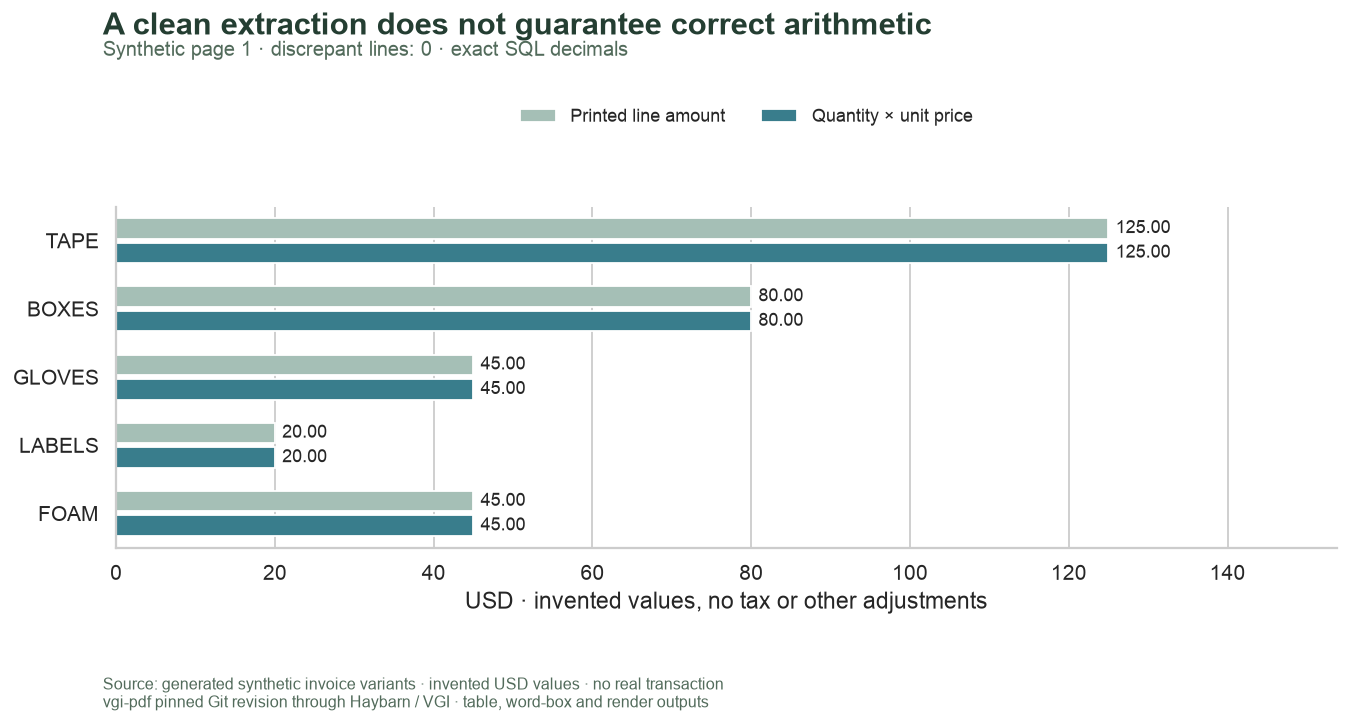

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.6))
y = list(range(len(lines)))
for column, offset, color, label in [
    ("printed_amount", -0.18, "#a5bfb6", "Printed line amount"),
    ("computed_amount", 0.18, "#397d8c", "Quantity × unit price"),
]:
    values = [float(v) for v in lines[column]]
    bars = ax.barh([i + offset for i in y], values, height=0.3, color=color, label=label)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], padding=4, fontsize=10)
ax.set_yticks(y, lines.sku)
ax.set_ylim(len(lines) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(float(lines.printed_amount.max()), float(lines.computed_amount.max())) * 1.23)
ax.set_xlabel("USD · invented values, no tax or other adjustments")
fig.legend(
    *ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.87), ncol=2, frameon=False, fontsize=10
)
finish(
    fig,
    f"amounts-page-{PAGE_NUMBER}",
    "A clean extraction does not guarantee correct arithmetic",
    f"Synthetic page {PAGE_NUMBER} · discrepant lines: {int(lines.discrepancy.sum())} · exact SQL decimals",
)

In [13]:
%%sql totals <<
SELECT count(*) AS lines,count(*) FILTER(WHERE discrepancy) AS discrepant_lines,
 sum(printed_amount) AS sum_printed_lines,sum(computed_amount) AS sum_computed_lines,
 (SELECT printed_total FROM invoice_total) AS printed_total,
 sum(computed_amount)-(SELECT printed_total FROM invoice_total) AS computed_minus_printed_total
FROM reconciled;

In [14]:
display(totals)
t = totals.iloc[0]
display(
    Markdown(
        f"The printed line amounts sum to **USD {t.sum_printed_lines:.2f}**, "
        f"matching the printed total of **USD {t.printed_total:.2f}**. "
        f"Recomputing quantity × unit price gives **USD {t.sum_computed_lines:.2f}**, "
        f"a signed difference of **USD {t.computed_minus_printed_total:+.2f}** from the printed total. "
        f"The row comparison flags **{int(t.discrepant_lines)} of {int(t.lines)} lines**. "
        + (
            "The printed subtotal check alone would miss the deliberately stale line amount."
            if int(t.discrepant_lines)
            else "Both printed-total and line-arithmetic checks agree in this baseline. "
            "The second page tests their difference."
        )
    )
)

,lines,discrepant_lines,sum_printed_lines,sum_computed_lines,printed_total,computed_minus_printed_total
0,5,0,315.0,315.0,315.0,0.0


The printed line amounts sum to **USD 315.00**, matching the printed total of **USD 315.00**. Recomputing quantity × unit price gives **USD 315.00**, a signed difference of **USD +0.00** from the printed total. The row comparison flags **0 of 5 lines**. Both printed-total and line-arithmetic checks agree in this baseline. The second page tests their difference.

## Validate extraction and reconciliation separately

Check that the intended table structure was recovered, fields parsed, item keys mapped uniquely to words, and coordinates fit the page. The arithmetic checks reconcile differences without requiring every line to be correct: the second page is deliberately inconsistent. The rendered PNG dimensions are also checked against page points at 144 DPI.

In [15]:
%%sql checks <<
SELECT 'page scalar agrees with page geometry count' AS check_name,
 (SELECT page_count FROM document)=(SELECT count(*) FROM page_geometry) AS passed
UNION ALL SELECT 'selected cell and word pages match the parameter',
 (SELECT bool_and(page={{PAGE_NUMBER}}) FROM cells) AND (SELECT bool_and(page={{PAGE_NUMBER}}) FROM words)
UNION ALL SELECT 'four known headers map to unique columns',count(*)=4 AND count(DISTINCT col)=4 AND bool_and(label IN('sku','qty','unit','amount')) FROM headers
UNION ALL SELECT 'cell addresses are unique',count(*)=count(DISTINCT(page,table_index,"row",col)) FROM cells
UNION ALL SELECT 'line item keys are unique and nonempty',count(*)>0 AND count(*)=count(DISTINCT sku) AND bool_and(sku<>'') FROM line_items
UNION ALL SELECT 'quantity and money fields parsed',bool_and(quantity IS NOT NULL AND quantity>0 AND unit_price IS NOT NULL AND unit_price>=0 AND printed_amount IS NOT NULL AND printed_amount>=0) FROM line_items
UNION ALL SELECT 'exactly one valid printed total was extracted',count(*)=1 AND bool_and(printed_total IS NOT NULL) FROM invoice_total
UNION ALL SELECT 'every word box fits its page',bool_and(w.x0>=0 AND w.top>=0 AND w.x1>w.x0 AND w.bottom>w.top AND w.x1<=p.width AND w.bottom<=p.height) FROM words w JOIN page_geometry p USING(page)
UNION ALL SELECT 'each item maps to one SKU word',count(*)=0 FROM(
 SELECT r.sku,count(w.text) AS n FROM reconciled r LEFT JOIN words w ON r.page=w.page AND r.sku=w.text GROUP BY r.sku HAVING n<>1)
UNION ALL SELECT 'printed line sum agrees with printed total',sum(printed_amount)=(SELECT printed_total FROM invoice_total) FROM reconciled
UNION ALL SELECT 'line differences reconcile to total difference',sum(difference)=sum(computed_amount)-(SELECT printed_total FROM invoice_total) FROM reconciled
UNION ALL SELECT 'discrepancy flags follow exact decimal differences',bool_and(discrepancy=(difference<>0)) FROM reconciled;

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
display(
    Markdown(
        f"All **{len(checks)} SQL checks** and the render-dimension check pass. "
        "The result preserves the distinction between extracted text and a document whose arithmetic agrees."
    )
)

,check_name,passed
0,page scalar agrees with page geometry count,True
1,selected cell and word pages match the parameter,True
2,four known headers map to unique columns,True
3,cell addresses are unique,True
4,line item keys are unique and nonempty,True
5,quantity and money fields parsed,True
6,exactly one valid printed total was extracted,True
7,every word box fits its page,True
8,each item maps to one SKU word,True
9,printed line sum agrees with printed total,True


All **12 SQL checks** and the render-dimension check pass. The result preserves the distinction between extracted text and a document whose arithmetic agrees.

## Try one change

Change `PAGE_NUMBER` from **1** to **2**, restart and run all. Predict that the changed quantity produces a line discrepancy even though the printed line amounts still sum to the printed total. Compare the typed rows, highlighted SKU and amount chart. The renderer and word coordinates should continue to agree. Restore **1** for the saved default.

This example assumes a known ruled table, unique SKU words, unrotated pages, exact two-decimal prices and no adjustments. It does not handle arbitrary invoices, scanned-image OCR, merged cells, duplicate item labels or business rules beyond the explicit formula. A table extraction that fails these assumptions needs review before arithmetic is interpreted.

In [17]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>